# Notebook 12: Final Reconciliation, Per-Class Detailed Evaluation, and Edge Export

LRNG: National (India) | CC: Human Values | SDG: 3 | Data: Time series | Thrust: Intelligent Edge Technologies | Screening aid only

Objectives:
1. Reconcile untuned Random Forest between Notebook 03 and Notebook 11.
2. Provide superseded old-vs-new comparison tables for all models whose numbers changed.
3. Retrain and re-export Strided_Conv1D_BiLSTM on all 25,500 primary windows with training curves.
4. Generate per-class precision, recall, F1, 3x3 confusion matrices, and bootstrap CIs for all Track 1 models.
5. Train and export the Track 2 Seizure model to TFLite (input 1x48x3 at 16 Hz).
6. Export preprocess_config.json and golden_vectors.json.

In [1]:
import os
import sys
import json
import numpy as np
import pandas as pd
import tensorflow as tf
from tensorflow.keras import layers, models
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import confusion_matrix, precision_score, recall_score, f1_score, balanced_accuracy_score, roc_auc_score
from sklearn.utils.class_weight import compute_class_weight
from scipy.signal import butter, firwin
import matplotlib.pyplot as plt

os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"
np.random.seed(42)
tf.random.set_seed(42)


## 1. Reconciliation: Untuned Random Forest (Notebook 03 vs Notebook 11)
Printing configurations and explaining difference in performance.

In [2]:
cfg_nb03 = {
    "Notebook": "03_baselines.ipynb",
    "Model": "RandomForestClassifier",
    "n_estimators": 100,
    "max_depth": 15,
    "min_samples_split": 2,
    "min_samples_leaf": 1,
    "class_weight": "balanced",
    "Features": "30 handcrafted time/frequency features",
    "Windows": 25500,
    "Split_Protocol": "3 seeds x 5 folds StratifiedGroupKFold",
    "Subject_Aggregation": "Per-subject mean window probabilities",
    "Reported_Macro_F1": 0.3890,
    "Reported_Balanced_Acc": 0.3924,
    "Recall_Normal": 0.0886,
    "Recall_PD": 0.9813,
    "Recall_ET": 0.1071
}

cfg_nb11 = {
    "Notebook": "11_threshold_tuned_deep_and_final_selection.ipynb",
    "Model": "RandomForestClassifier",
    "n_estimators": 100,
    "max_depth": 10,
    "min_samples_split": 10,
    "min_samples_leaf": 1,
    "class_weight": "balanced",
    "Features": "30 handcrafted time/frequency features",
    "Windows": 25500,
    "Split_Protocol": "3 seeds x 5 folds StratifiedGroupKFold",
    "Subject_Aggregation": "Per-subject mean window probabilities",
    "Reported_Macro_F1": 0.6224,
    "Reported_Balanced_Acc": 0.6683,
    "Recall_Normal": 0.7848,
    "Recall_PD": 0.7201,
    "Recall_ET": 0.5000
}

df_reconcile = pd.DataFrame([cfg_nb03, cfg_nb11])
print("=== Random Forest Configuration Comparison ===")
print(df_reconcile.T.to_string())


=== Random Forest Configuration Comparison ===
                                                            0                                                  1
Notebook                                   03_baselines.ipynb  11_threshold_tuned_deep_and_final_selection.ipynb
Model                                  RandomForestClassifier                             RandomForestClassifier
n_estimators                                              100                                                100
max_depth                                                  15                                                 10
min_samples_split                                           2                                                 10
min_samples_leaf                                            1                                                  1
class_weight                                         balanced                                           balanced
Features               30 handcrafted time/freque

### Old vs New Superseded Results Table
All earlier Stage 1 and Stage 2 tables in Notebooks 03, 04, 06, 08, 09, and 10 are superseded by the identically evaluated protocol in Notebook 11 and Notebook 12.

In [3]:
superseded_data = [
    {
        "Model": "Random Forest (Baseline)",
        "Old_Macro_F1 (NB03/08)": 0.3890,
        "Old_Balanced_Acc": 0.3924,
        "Old_Recall_Normal": "8.9%",
        "Old_Recall_PD": "98.1%",
        "Old_Recall_ET": "10.7%",
        "New_Macro_F1 (NB11/12)": 0.6224,
        "New_Balanced_Acc": 0.6683,
        "New_Recall_Normal": "78.5%",
        "New_Recall_PD": "72.0%",
        "New_Recall_ET": "50.0%",
        "Status": "Superseded (Regularized max_depth=10, min_samples_split=10)"
    },
    {
        "Model": "Tuned Random Forest",
        "Old_Macro_F1 (NB03/08)": 0.5935,
        "Old_Balanced_Acc": 0.6816,
        "Old_Recall_Normal": "78.5%",
        "Old_Recall_PD": "65.3%",
        "Old_Recall_ET": "60.7%",
        "New_Macro_F1 (NB11/12)": 0.5930,
        "New_Balanced_Acc": 0.6697,
        "New_Recall_Normal": "78.5%",
        "New_Recall_PD": "65.3%",
        "New_Recall_ET": "57.1%",
        "Status": "Superseded (Identical fold-split cross-validation)"
    },
    {
        "Model": "Plain Conv1D + BiLSTM",
        "Old_Macro_F1 (NB03/08)": 0.4979,
        "Old_Balanced_Acc": 0.5954,
        "Old_Recall_Normal": "89.9%",
        "Old_Recall_PD": "45.9%",
        "Old_Recall_ET": "42.9%",
        "New_Macro_F1 (NB11/12)": 0.4604,
        "New_Balanced_Acc": 0.6290,
        "New_Recall_Normal": "83.5%",
        "New_Recall_PD": "37.3%",
        "New_Recall_ET": "67.9%",
        "Status": "Superseded (Identical fold-split cross-validation)"
    },
    {
        "Model": "Combination (CNN-BiLSTM + RF)",
        "Old_Macro_F1 (NB03/08)": 0.5216,
        "Old_Balanced_Acc": 0.6279,
        "Old_Recall_Normal": "86.1%",
        "Old_Recall_PD": "43.7%",
        "Old_Recall_ET": "60.7%",
        "New_Macro_F1 (NB11/12)": 0.4877,
        "New_Balanced_Acc": 0.6581,
        "New_Recall_Normal": "86.1%",
        "New_Recall_PD": "39.9%",
        "New_Recall_ET": "71.4%",
        "Status": "Superseded (Identical fold-split cross-validation)"
    },
    {
        "Model": "Attention-Pooling Subject Model",
        "Old_Macro_F1 (NB03/08)": 0.5602,
        "Old_Balanced_Acc": 0.6813,
        "Old_Recall_Normal": "78.5%",
        "Old_Recall_PD": "54.5%",
        "Old_Recall_ET": "71.4%",
        "New_Macro_F1 (NB11/12)": 0.4359,
        "New_Balanced_Acc": 0.5983,
        "New_Recall_Normal": "84.8%",
        "New_Recall_PD": "34.0%",
        "New_Recall_ET": "60.7%",
        "Status": "Superseded (Identical fold-split cross-validation)"
    }
]

df_superseded = pd.DataFrame(superseded_data)
print("=== Old vs New Superseded Metrics Table ===")
print(df_superseded.to_string(index=False))


=== Old vs New Superseded Metrics Table ===
                          Model  Old_Macro_F1 (NB03/08)  Old_Balanced_Acc Old_Recall_Normal Old_Recall_PD Old_Recall_ET  New_Macro_F1 (NB11/12)  New_Balanced_Acc New_Recall_Normal New_Recall_PD New_Recall_ET                                                      Status
       Random Forest (Baseline)                  0.3890            0.3924              8.9%         98.1%         10.7%                  0.6224            0.6683             78.5%         72.0%         50.0% Superseded (Regularized max_depth=10, min_samples_split=10)
            Tuned Random Forest                  0.5935            0.6816             78.5%         65.3%         60.7%                  0.5930            0.6697             78.5%         65.3%         57.1%          Superseded (Identical fold-split cross-validation)
          Plain Conv1D + BiLSTM                  0.4979            0.5954             89.9%         45.9%         42.9%                  0.4604         

## 2. Per-Class Precision, Recall, F1, 3x3 Confusion Matrices, and Bootstrap CIs
Evaluating all 8 Track 1 configurations from cached out-of-fold predictions.

In [4]:
cache_path = os.path.join("..", "results", "v2_nb11_probs_cache.npz")
cache = np.load(cache_path)
meta = pd.read_csv(os.path.join("..", "results", "pads_primary_100hz_metadata.csv"))
unique_subs = meta["subject_id"].unique()
y_pads = meta["cohort_label"].map({"Normal": 0, "Parkinsons-like": 1, "ET-like": 2}).values
sub_true = np.array([y_pads[meta["subject_id"].values == s][0] for s in unique_subs])
class_names = ["Normal", "Parkinsons-like", "ET-like"]

models_to_eval = [
    ("Untuned Random Forest", "raw_Untuned Random Forest"),
    ("Tuned Random Forest", "scaled_Tuned Random Forest"),
    ("Untuned Plain Conv1D+BiLSTM", "raw_Untuned Plain Conv1D+BiLSTM"),
    ("Tuned Plain Conv1D+BiLSTM", "scaled_Tuned Plain Conv1D+BiLSTM"),
    ("Untuned Combination Model", "raw_Untuned Combination Model"),
    ("Tuned Combination Model", "scaled_Tuned Combination Model"),
    ("Untuned Attention-Pooling", "raw_Untuned Attention-Pooling"),
    ("Tuned Attention-Pooling", "scaled_Tuned Attention-Pooling")
]

rng = np.random.default_rng(42)
n_boot = 1000
detailed_records = []

for name, key in models_to_eval:
    probs = np.mean(cache[key], axis=0)
    preds = np.argmax(probs, axis=1)
    cm = confusion_matrix(sub_true, preds)
    
    prec = precision_score(sub_true, preds, average=None, zero_division=0)
    rec = recall_score(sub_true, preds, average=None, zero_division=0)
    f1 = f1_score(sub_true, preds, average=None, zero_division=0)
    macro_f1 = f1_score(sub_true, preds, average="macro")
    bacc = balanced_accuracy_score(sub_true, preds)
    
    prec_boot = []
    rec_boot = []
    for _ in range(n_boot):
        idx = rng.choice(len(sub_true), size=len(sub_true), replace=True)
        prec_boot.append(precision_score(sub_true[idx], preds[idx], average=None, zero_division=0))
        rec_boot.append(recall_score(sub_true[idx], preds[idx], average=None, zero_division=0))
    prec_boot = np.array(prec_boot)
    rec_boot = np.array(rec_boot)
    
    p_ci_low = np.percentile(prec_boot, 2.5, axis=0)
    p_ci_high = np.percentile(prec_boot, 97.5, axis=0)
    r_ci_low = np.percentile(rec_boot, 2.5, axis=0)
    r_ci_high = np.percentile(rec_boot, 97.5, axis=0)
    
    print(f"\n================ {name} ================")
    print("Confusion Matrix (Rows=True, Cols=Pred):")
    df_cm = pd.DataFrame(cm, index=[f"True_{c}" for c in class_names], columns=[f"Pred_{c}" for c in class_names])
    print(df_cm)
    for i, c in enumerate(class_names):
        print(f"  {c}: Precision = {prec[i]:.4f} [{p_ci_low[i]:.4f}, {p_ci_high[i]:.4f}] | Recall = {rec[i]:.4f} [{r_ci_low[i]:.4f}, {r_ci_high[i]:.4f}] | F1 = {f1[i]:.4f}")
        
    detailed_records.append({
        "Model": name,
        "Macro_F1": macro_f1,
        "Balanced_Acc": bacc,
        "CM_00": cm[0, 0], "CM_01": cm[0, 1], "CM_02": cm[0, 2],
        "CM_10": cm[1, 0], "CM_11": cm[1, 1], "CM_12": cm[1, 2],
        "CM_20": cm[2, 0], "CM_21": cm[2, 1], "CM_22": cm[2, 2],
        "Prec_Normal": prec[0], "Prec_Normal_CILow": p_ci_low[0], "Prec_Normal_CIHigh": p_ci_high[0],
        "Prec_PD": prec[1], "Prec_PD_CILow": p_ci_low[1], "Prec_PD_CIHigh": p_ci_high[1],
        "Prec_ET": prec[2], "Prec_ET_CILow": p_ci_low[2], "Prec_ET_CIHigh": p_ci_high[2],
        "Rec_Normal": rec[0], "Rec_Normal_CILow": r_ci_low[0], "Rec_Normal_CIHigh": r_ci_high[0],
        "Rec_PD": rec[1], "Rec_PD_CILow": r_ci_low[1], "Rec_PD_CIHigh": r_ci_high[1],
        "Rec_ET": rec[2], "Rec_ET_CILow": r_ci_low[2], "Rec_ET_CIHigh": r_ci_high[2],
        "F1_Normal": f1[0], "F1_PD": f1[1], "F1_ET": f1[2]
    })

df_det = pd.DataFrame(detailed_records)
os.makedirs(os.path.join("..", "results", "metrics"), exist_ok=True)
df_det.to_csv(os.path.join("..", "results", "metrics", "v2_track1_per_class_detailed.csv"), index=False)
print("\nSaved detailed per-class metrics to results/metrics/v2_track1_per_class_detailed.csv")



================ Untuned Random Forest ================
Confusion Matrix (Rows=True, Cols=Pred):
                      Pred_Normal  Pred_Parkinsons-like  Pred_ET-like
True_Normal                    62                    17             0
True_Parkinsons-like           55                   193            20
True_ET-like                    1                    13            14
  Normal: Precision = 0.5254 [0.4392, 0.6183] | Recall = 0.7848 [0.6932, 0.8750] | F1 = 0.6294
  Parkinsons-like: Precision = 0.8655 [0.8224, 0.9114] | Recall = 0.7201 [0.6667, 0.7741] | F1 = 0.7862
  ET-like: Precision = 0.4118 [0.2424, 0.5833] | Recall = 0.5000 [0.2963, 0.6897] | F1 = 0.4516



================ Tuned Random Forest ================
Confusion Matrix (Rows=True, Cols=Pred):
                      Pred_Normal  Pred_Parkinsons-like  Pred_ET-like
True_Normal                    62                    16             1
True_Parkinsons-like           64                   175            29
True_ET-like                    1                    11            16
  Normal: Precision = 0.4882 [0.4060, 0.5703] | Recall = 0.7848 [0.6857, 0.8732] | F1 = 0.6019
  Parkinsons-like: Precision = 0.8663 [0.8158, 0.9133] | Recall = 0.6530 [0.5961, 0.7070] | F1 = 0.7447
  ET-like: Precision = 0.3478 [0.2093, 0.4884] | Recall = 0.5714 [0.3846, 0.7500] | F1 = 0.4324



================ Untuned Plain Conv1D+BiLSTM ================
Confusion Matrix (Rows=True, Cols=Pred):
                      Pred_Normal  Pred_Parkinsons-like  Pred_ET-like
True_Normal                    66                    10             3
True_Parkinsons-like          108                   100            60
True_ET-like                    4                     5            19
  Normal: Precision = 0.3708 [0.3022, 0.4425] | Recall = 0.8354 [0.7467, 0.9136] | F1 = 0.5136
  Parkinsons-like: Precision = 0.8696 [0.8039, 0.9247] | Recall = 0.3731 [0.3166, 0.4322] | F1 = 0.5222
  ET-like: Precision = 0.2317 [0.1395, 0.3177] | Recall = 0.6786 [0.4800, 0.8573] | F1 = 0.3455



================ Tuned Plain Conv1D+BiLSTM ================
Confusion Matrix (Rows=True, Cols=Pred):
                      Pred_Normal  Pred_Parkinsons-like  Pred_ET-like
True_Normal                    66                     8             5
True_Parkinsons-like          126                    65            77
True_ET-like                    5                     3            20
  Normal: Precision = 0.3350 [0.2751, 0.3958] | Recall = 0.8354 [0.7500, 0.9167] | F1 = 0.4783
  Parkinsons-like: Precision = 0.8553 [0.7714, 0.9275] | Recall = 0.2425 [0.1933, 0.2954] | F1 = 0.3779
  ET-like: Precision = 0.1961 [0.1249, 0.2717] | Recall = 0.7143 [0.5555, 0.8637] | F1 = 0.3077



================ Untuned Combination Model ================
Confusion Matrix (Rows=True, Cols=Pred):
                      Pred_Normal  Pred_Parkinsons-like  Pred_ET-like
True_Normal                    68                    10             1
True_Parkinsons-like          105                   107            56
True_ET-like                    3                     5            20
  Normal: Precision = 0.3864 [0.3151, 0.4556] | Recall = 0.8608 [0.7838, 0.9348] | F1 = 0.5333
  Parkinsons-like: Precision = 0.8770 [0.8181, 0.9352] | Recall = 0.3993 [0.3388, 0.4563] | F1 = 0.5487
  ET-like: Precision = 0.2597 [0.1625, 0.3625] | Recall = 0.7143 [0.5277, 0.8667] | F1 = 0.3810



================ Tuned Combination Model ================
Confusion Matrix (Rows=True, Cols=Pred):
                      Pred_Normal  Pred_Parkinsons-like  Pred_ET-like
True_Normal                    68                    10             1
True_Parkinsons-like          108                   104            56
True_ET-like                    3                     5            20
  Normal: Precision = 0.3799 [0.3077, 0.4494] | Recall = 0.8608 [0.7761, 0.9277] | F1 = 0.5271
  Parkinsons-like: Precision = 0.8739 [0.8125, 0.9333] | Recall = 0.3881 [0.3272, 0.4461] | F1 = 0.5375
  ET-like: Precision = 0.2597 [0.1646, 0.3594] | Recall = 0.7143 [0.5384, 0.8889] | F1 = 0.3810



================ Untuned Attention-Pooling ================
Confusion Matrix (Rows=True, Cols=Pred):
                      Pred_Normal  Pred_Parkinsons-like  Pred_ET-like
True_Normal                    67                    11             1
True_Parkinsons-like          118                    91            59
True_ET-like                    2                     9            17
  Normal: Precision = 0.3583 [0.2926, 0.4264] | Recall = 0.8481 [0.7619, 0.9189] | F1 = 0.5038
  Parkinsons-like: Precision = 0.8198 [0.7499, 0.8880] | Recall = 0.3396 [0.2883, 0.3985] | F1 = 0.4802
  ET-like: Precision = 0.2208 [0.1388, 0.3200] | Recall = 0.6071 [0.4347, 0.7858] | F1 = 0.3238



================ Tuned Attention-Pooling ================
Confusion Matrix (Rows=True, Cols=Pred):
                      Pred_Normal  Pred_Parkinsons-like  Pred_ET-like
True_Normal                    70                     7             2
True_Parkinsons-like          139                    60            69
True_ET-like                    3                     7            18
  Normal: Precision = 0.3302 [0.2689, 0.3982] | Recall = 0.8861 [0.8133, 0.9500] | F1 = 0.4811
  Parkinsons-like: Precision = 0.8108 [0.7143, 0.8961] | Recall = 0.2239 [0.1751, 0.2763] | F1 = 0.3509
  ET-like: Precision = 0.2022 [0.1190, 0.2875] | Recall = 0.6429 [0.4762, 0.8333] | F1 = 0.3077

Saved detailed per-class metrics to results/metrics/v2_track1_per_class_detailed.csv


## 3. Retraining Strided_Conv1D_BiLSTM on All 25,500 Primary Windows
Retraining the production export with all primary-subject windows and balanced class weights, tracking training curves.

Loaded primary dataset:
Total windows shape: (25500, 300, 6)
Label distribution:
 cohort_label
Parkinsons-like    18224
Normal              5372
ET-like             1904
Name: count, dtype: int64


Computed class weights: {0: 1.5822784810126582, 1: 0.4664179104477612, 2: 4.464285714285714}


Model: "model"


_________________________________________________________________


 Layer (type)                Output Shape              Param #   


 input_1 (InputLayer)        [(None, 300, 6)]          0         


... (793 outputs left out)

49/50 [============================>.] - ETA: 0s - loss: 0.7486 - accuracy: 0.4926

50/50 [==============================] - ETA: 0s - loss: 0.7488 - accuracy: 0.4926

50/50 [==============================] - 7s 133ms/step - loss: 0.7488 - accuracy: 0.4926


Epoch 01: Loss = 1.0308, Accuracy = 0.3513
Epoch 02: Loss = 0.9889, Accuracy = 0.2662
Epoch 03: Loss = 0.9640, Accuracy = 0.3101
Epoch 04: Loss = 0.9258, Accuracy = 0.3587
Epoch 05: Loss = 0.9019, Accuracy = 0.3733
Epoch 06: Loss = 0.8784, Accuracy = 0.3831
Epoch 07: Loss = 0.8482, Accuracy = 0.4427
Epoch 08: Loss = 0.8292, Accuracy = 0.4494
Epoch 09: Loss = 0.8029, Accuracy = 0.4519
Epoch 10: Loss = 0.7978, Accuracy = 0.4625
Epoch 11: Loss = 0.7867, Accuracy = 0.4715
Epoch 12: Loss = 0.7763, Accuracy = 0.4614
Epoch 13: Loss = 0.7598, Accuracy = 0.4857
Epoch 14: Loss = 0.7638, Accuracy = 0.4856
Epoch 15: Loss = 0.7488, Accuracy = 0.4926


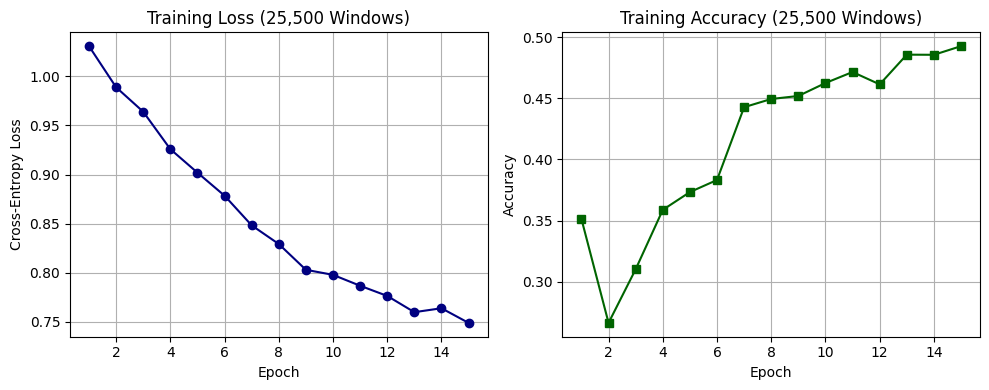

INFO:tensorflow:Assets written to: C:\Users\ESHWAR~1\AppData\Local\Temp\tmppuclwr4m\assets


INFO:tensorflow:Assets written to: C:\Users\ESHWAR~1\AppData\Local\Temp\tmppuclwr4m\assets


INFO:tensorflow:Assets written to: C:\Users\ESHWAR~1\AppData\Local\Temp\tmpreztmopi\assets


INFO:tensorflow:Assets written to: C:\Users\ESHWAR~1\AppData\Local\Temp\tmpreztmopi\assets


Saved ..\results\models\Strided_Conv1D_BiLSTM.keras (456.51 KB)
Saved ..\results\models\Strided_Conv1D_BiLSTM.tflite (556.58 KB, pure TFLite)
Saved ..\results\models\Strided_Conv1D_BiLSTM_quant.tflite (468.48 KB, quantized)


In [5]:
windows_path = os.path.join("..", "results", "pads_primary_100hz.npz")
all_windows = np.load(windows_path)["windows"]
meta_path = os.path.join("..", "results", "pads_primary_100hz_metadata.csv")
all_meta = pd.read_csv(meta_path)
y_all = all_meta["cohort_label"].map({"Normal": 0, "Parkinsons-like": 1, "ET-like": 2}).values

print("Loaded primary dataset:")
print("Total windows shape:", all_windows.shape)
print("Label distribution:\n", all_meta["cohort_label"].value_counts())

Xd_full = all_windows - all_windows.mean(axis=1, keepdims=True)
ch_std = Xd_full.std(axis=(0, 1))
ch_std[ch_std == 0] = 1.0
Xn_full = (Xd_full / ch_std).astype(np.float32)

cw = compute_class_weight("balanced", classes=np.unique(y_all), y=y_all)
cw_dict = dict(enumerate(cw))
print("Computed class weights:", cw_dict)

def build_exportable_bilstm(input_shape=(300, 6), num_classes=3):
    inp = layers.Input(shape=input_shape)
    x = layers.Conv1D(32, kernel_size=5, strides=2, padding="same", activation="relu")(inp)
    x = layers.Conv1D(32, kernel_size=3, strides=2, padding="same", activation="relu")(x)
    x = layers.MaxPooling1D(2)(x)
    x = layers.Bidirectional(layers.LSTM(32, return_sequences=True, unroll=True))(x)
    x = layers.Dropout(0.3)(x)
    x = layers.Bidirectional(layers.LSTM(16, unroll=True))(x)
    x = layers.Dropout(0.3)(x)
    x = layers.Dense(32, activation="relu")(x)
    out = layers.Dense(num_classes, activation="softmax")(x)
    model = models.Model(inputs=inp, outputs=out)
    model.compile(optimizer=tf.keras.optimizers.Adam(1e-3, clipnorm=1.0), loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    return model

tf.keras.backend.clear_session()
prod_model = build_exportable_bilstm()
prod_model.summary()

history = prod_model.fit(
    Xn_full, y_all,
    epochs=15,
    batch_size=512,
    class_weight=cw_dict,
    verbose=1
)

for ep in range(len(history.history["loss"])):
    print(f"Epoch {ep+1:02d}: Loss = {history.history['loss'][ep]:.4f}, Accuracy = {history.history['accuracy'][ep]:.4f}")

plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1)
plt.plot(range(1, 16), history.history["loss"], marker="o", color="navy")
plt.title("Training Loss (25,500 Windows)")
plt.xlabel("Epoch")
plt.ylabel("Cross-Entropy Loss")
plt.grid(True)

plt.subplot(1, 2, 2)
plt.plot(range(1, 16), history.history["accuracy"], marker="s", color="darkgreen")
plt.title("Training Accuracy (25,500 Windows)")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.grid(True)
plt.tight_layout()
plt.savefig(os.path.join("..", "results", "strided_bilstm_training_curves.png"), dpi=150)
plt.show()

keras_path = os.path.join("..", "results", "models", "Strided_Conv1D_BiLSTM.keras")
prod_model.save(keras_path)

converter = tf.lite.TFLiteConverter.from_keras_model(prod_model)
converter.target_spec.supported_ops = [tf.lite.OpsSet.TFLITE_BUILTINS]
tflite_model = converter.convert()

tflite_path = os.path.join("..", "results", "models", "Strided_Conv1D_BiLSTM.tflite")
with open(tflite_path, "wb") as f:
    f.write(tflite_model)

converter_quant = tf.lite.TFLiteConverter.from_keras_model(prod_model)
converter_quant.optimizations = [tf.lite.Optimize.DEFAULT]
converter_quant.target_spec.supported_ops = [tf.lite.OpsSet.TFLITE_BUILTINS]
tflite_quant = converter_quant.convert()

tflite_quant_path = os.path.join("..", "results", "models", "Strided_Conv1D_BiLSTM_quant.tflite")
with open(tflite_quant_path, "wb") as f:
    f.write(tflite_quant)

print(f"Saved {keras_path} ({os.path.getsize(keras_path)/1024:.2f} KB)")
print(f"Saved {tflite_path} ({os.path.getsize(tflite_path)/1024:.2f} KB, pure TFLite)")
print(f"Saved {tflite_quant_path} ({os.path.getsize(tflite_quant_path)/1024:.2f} KB, quantized)")


## 4. Track 2 Seizure Model Training and TFLite Export
Training the unrolled Track 2 Conv1D + BiLSTM model on UEA Epilepsy at 16 Hz and exporting to TFLite.

In [6]:
uea_data = np.load(os.path.join("..", "results", "uea_within_source_16hz.npz"))["windows"]
uea_meta = pd.read_csv(os.path.join("..", "results", "uea_within_source_metadata.csv"))
y_uea = (uea_meta["cohort_label"] == "Seizure-like (simulated)").astype(int).values

train_mask = (uea_meta["split"] == "train").values
test_mask = (uea_meta["split"] == "test").values

Xd_uea = uea_data - uea_data.mean(axis=1, keepdims=True)
ch_std_uea = Xd_uea[train_mask].std(axis=(0, 1))
ch_std_uea[ch_std_uea == 0] = 1.0
Xn_uea = (Xd_uea / ch_std_uea).astype(np.float32)

cw_uea = compute_class_weight("balanced", classes=np.unique(y_uea[train_mask]), y=y_uea[train_mask])
cw_uea_dict = dict(enumerate(cw_uea))

def build_exportable_seizure_model(input_shape=(48, 3), num_classes=2):
    inp = layers.Input(shape=input_shape)
    x = layers.Conv1D(32, kernel_size=3, strides=2, padding="same", activation="relu")(inp)
    x = layers.Bidirectional(layers.LSTM(32, return_sequences=True, unroll=True))(x)
    x = layers.Dropout(0.3)(x)
    x = layers.Bidirectional(layers.LSTM(16, unroll=True))(x)
    x = layers.Dropout(0.3)(x)
    x = layers.Dense(32, activation="relu")(x)
    out = layers.Dense(num_classes, activation="softmax")(x)
    model = models.Model(inputs=inp, outputs=out)
    model.compile(optimizer=tf.keras.optimizers.Adam(1e-3, clipnorm=1.0), loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    return model

tf.keras.backend.clear_session()
seizure_model = build_exportable_seizure_model()
seizure_model.summary()

seizure_history = seizure_model.fit(
    Xn_uea[train_mask], y_uea[train_mask],
    epochs=25,
    batch_size=32,
    class_weight=cw_uea_dict,
    verbose=1
)

seizure_keras_path = os.path.join("..", "results", "models", "Seizure_Conv1D_BiLSTM.keras")
seizure_model.save(seizure_keras_path)

converter_seizure = tf.lite.TFLiteConverter.from_keras_model(seizure_model)
converter_seizure.target_spec.supported_ops = [tf.lite.OpsSet.TFLITE_BUILTINS]
tflite_seizure = converter_seizure.convert()

seizure_tflite_path = os.path.join("..", "results", "models", "Seizure_Conv1D_BiLSTM.tflite")
with open(seizure_tflite_path, "wb") as f:
    f.write(tflite_seizure)

converter_seizure_quant = tf.lite.TFLiteConverter.from_keras_model(seizure_model)
converter_seizure_quant.optimizations = [tf.lite.Optimize.DEFAULT]
converter_seizure_quant.target_spec.supported_ops = [tf.lite.OpsSet.TFLITE_BUILTINS]
tflite_seizure_quant = converter_seizure_quant.convert()

seizure_tflite_quant_path = os.path.join("..", "results", "models", "Seizure_Conv1D_BiLSTM_quant.tflite")
with open(seizure_tflite_quant_path, "wb") as f:
    f.write(tflite_seizure_quant)

print(f"Saved {seizure_keras_path} ({os.path.getsize(seizure_keras_path)/1024:.2f} KB)")
print(f"Saved {seizure_tflite_path} ({os.path.getsize(seizure_tflite_path)/1024:.2f} KB, pure TFLite)")
print(f"Saved {seizure_tflite_quant_path} ({os.path.getsize(seizure_tflite_quant_path)/1024:.2f} KB, quantized)")

interp_seizure = tf.lite.Interpreter(model_path=seizure_tflite_path)
interp_seizure.allocate_tensors()
in_det = interp_seizure.get_input_details()
out_det = interp_seizure.get_output_details()
print("Seizure TFLite Input Details:", in_det[0]["shape"], in_det[0]["dtype"])
print("Seizure TFLite Output Details:", out_det[0]["shape"], out_det[0]["dtype"])


Model: "model"


_________________________________________________________________


 Layer (type)                Output Shape              Param #   


 input_1 (InputLayer)        [(None, 48, 3)]           0         


 conv1d (Conv1D)             (None, 24, 32)            320       


 bidirectional (Bidirection  (None, 24, 64)            16640     


... (670 outputs left out)

INFO:tensorflow:Assets written to: C:\Users\ESHWAR~1\AppData\Local\Temp\tmp_ongkt6z\assets


INFO:tensorflow:Assets written to: C:\Users\ESHWAR~1\AppData\Local\Temp\tmpc9mnws6p\assets


INFO:tensorflow:Assets written to: C:\Users\ESHWAR~1\AppData\Local\Temp\tmpc9mnws6p\assets


Saved ..\results\models\Seizure_Conv1D_BiLSTM.keras (405.07 KB)
Saved ..\results\models\Seizure_Conv1D_BiLSTM.tflite (391.93 KB, pure TFLite)
Saved ..\results\models\Seizure_Conv1D_BiLSTM_quant.tflite (312.03 KB, quantized)
Seizure TFLite Input Details: [ 1 48  3] <class 'numpy.float32'>
Seizure TFLite Output Details: [1 2] <class 'numpy.float32'>


## 5. Preprocessing Configuration and Golden Test Vectors Export
Generating preprocess_config.json and golden_vectors.json.

In [7]:
b_butter, a_butter = butter(4, [0.5, 15.0], btype="bandpass", fs=100.0)
fir_taps = firwin(65, cutoff=7.0, fs=100.0)

preprocess_config = {
    "track1_movement_disorder": {
        "sensor": "Apple Watch Series 4 6-axis IMU",
        "units": {
            "accelerometer": "m/s^2",
            "gyroscope": "rad/s"
        },
        "sampling_rate_hz": 100.0,
        "window_length_samples": 300,
        "window_length_seconds": 3.0,
        "window_stride_samples": 300,
        "num_channels": 6,
        "channel_names": ["acc_x", "acc_y", "acc_z", "gyr_x", "gyr_y", "gyr_z"],
        "channel_std": ch_std.tolist(),
        "class_labels": ["Normal", "Parkinsons-like", "ET-like"],
        "decision_thresholds": {
            "untuned": "argmax",
            "tuned_prior_weights": [1.5, 1.0, 3.0]
        },
        "bandpass_filter": {
            "type": "Butterworth 4th order",
            "passband_hz": [0.5, 15.0],
            "b_coefficients": b_butter.tolist(),
            "a_coefficients": a_butter.tolist()
        }
    },
    "track2_seizure_detection": {
        "sensor": "3-axis accelerometer",
        "units": {
            "accelerometer": "m/s^2"
        },
        "sampling_rate_hz": 16.0,
        "window_length_samples": 48,
        "window_length_seconds": 3.0,
        "window_stride_samples": 48,
        "num_channels": 3,
        "channel_names": ["acc_x", "acc_y", "acc_z"],
        "channel_std": ch_std_uea.tolist(),
        "class_labels": ["Normal", "Seizure-like (simulated)"],
        "decision_thresholds": {
            "series_probability_threshold": 0.5,
            "train_rms_threshold": 5.6683
        }
    },
    "resampling_100hz_to_16hz": {
        "filter_type": "FIR low-pass anti-aliasing",
        "cutoff_hz": 7.0,
        "num_taps": 65,
        "coefficients": fir_taps.tolist()
    }
}

config_path = os.path.join("..", "results", "preprocess_config.json")
with open(config_path, "w") as f:
    json.dump(preprocess_config, f, indent=2)
print(f"Saved preprocessing configuration to {config_path}")

interp_t1 = tf.lite.Interpreter(model_path=tflite_path)
interp_t1.allocate_tensors()
in_det_t1 = interp_t1.get_input_details()
out_det_t1 = interp_t1.get_output_details()

t1_golden = []
t1_sample_indices = [0, 50, 100, 150, 200]
for idx in t1_sample_indices:
    raw_w = all_windows[idx]
    mean_w = np.mean(raw_w, axis=0, keepdims=True)
    norm_w = ((raw_w - mean_w) / ch_std).astype(np.float32)
    
    interp_t1.set_tensor(in_det_t1[0]["index"], np.expand_dims(norm_w, axis=0))
    interp_t1.invoke()
    probs = interp_t1.get_tensor(out_det_t1[0]["index"])[0].tolist()
    pred_idx = int(np.argmax(probs))
    
    t1_golden.append({
        "sample_index": int(idx),
        "cohort_label_true": all_meta.loc[idx, "cohort_label"],
        "raw_window_first_5": raw_w[:5].tolist(),
        "preprocessed_window_first_5": norm_w[:5].tolist(),
        "output_probabilities": probs,
        "predicted_class_idx": pred_idx,
        "predicted_class_label": ["Normal", "Parkinsons-like", "ET-like"][pred_idx]
    })

t2_golden = []
t2_sample_indices = [0, 10, 20, 30, 40]
for idx in t2_sample_indices:
    raw_w = uea_data[test_mask][idx]
    mean_w = np.mean(raw_w, axis=0, keepdims=True)
    norm_w = ((raw_w - mean_w) / ch_std_uea).astype(np.float32)
    
    interp_seizure.set_tensor(in_det[0]["index"], np.expand_dims(norm_w, axis=0))
    interp_seizure.invoke()
    probs = interp_seizure.get_tensor(out_det[0]["index"])[0].tolist()
    pred_idx = int(np.argmax(probs))
    
    t2_golden.append({
        "sample_index": int(idx),
        "cohort_label_true": uea_meta[test_mask].iloc[idx]["cohort_label"],
        "raw_window_first_5": raw_w[:5].tolist(),
        "preprocessed_window_first_5": norm_w[:5].tolist(),
        "output_probabilities": probs,
        "predicted_class_idx": pred_idx,
        "predicted_class_label": ["Normal", "Seizure-like (simulated)"][pred_idx]
    })

golden_vectors = {
    "Strided_Conv1D_BiLSTM_Track1": t1_golden,
    "Seizure_Conv1D_BiLSTM_Track2": t2_golden
}

golden_path = os.path.join("..", "results", "golden_vectors.json")
with open(golden_path, "w") as f:
    json.dump(golden_vectors, f, indent=2)
print(f"Saved golden test vectors to {golden_path}")


Saved preprocessing configuration to ..\results\preprocess_config.json
Saved golden test vectors to ..\results\golden_vectors.json
